# Global Solution – MLAM (CitizenTech)
## Saneamento básico e mortalidade infantil nos municípios brasileiros

**Problema:** a falta de saneamento básico (água e esgoto adequados, coleta de lixo) é apontada como um dos determinantes
da mortalidade infantil. Investigamos, com dados reais dos **5.565 municípios brasileiros (Censo 2010)**, o quanto a
mortalidade infantil está associada às condições de saneamento, renda e educação — informação útil para priorizar
investimentos públicos em cidades e comunidades (ODS 3 – Saúde e ODS 6 – Água e Saneamento).

**Base:** Atlas do Desenvolvimento Humano no Brasil (PNUD / IPEA / FJP), preparada por `01_preparacao_dados.py`.

| Variável | Descrição |
|---|---|
| `mort_infantil` | Mortalidade infantil (óbitos < 1 ano por mil nascidos vivos) |
| `pct_agua_esgoto_inadeq` | % da população em domicílios com abastecimento de água e esgotamento sanitário inadequados |
| `pct_coleta_lixo` | % da população em domicílios urbanos com coleta de lixo |
| `renda_per_capita` | Renda domiciliar per capita média (R$ de ago/2010) |
| `pct_analf_18mais` | Taxa de analfabetismo da população de 18 anos ou mais (%) |
| `pct_urbanizacao` | % da população residente em área urbana |

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

RAIZ = Path.cwd() if (Path.cwd() / "dados").exists() else Path.cwd().parent
FIG = RAIZ / "figuras"; FIG.mkdir(exist_ok=True)
RES = {}  # resultados numéricos usados no relatório
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv(RAIZ / "dados" / "atlas_municipios_2010.csv")
print(df.shape)
df.head()

(5565, 17)


,cod_ibge,municipio,cod_uf,uf,mort_infantil,pct_agua_esgoto_inadeq,pct_coleta_lixo,pct_agua_encanada,renda_per_capita,pct_analf_18mais,anos_estudo_esperados,gini,pct_extremamente_pobres,idhm,populacao,populacao_urbana,pct_urbanizacao
0,1100015,ALTA FLORESTA D'OESTE,11,Rondônia,23.8,9.31,94.05,93.69,476.99,13.00,8.67,0.58,14.29,0.641,24392,13970,57.27
1,1100023,ARIQUEMES,11,Rondônia,19.2,11.40,96.72,98.54,689.95,8.53,9.18,0.53,4.36,0.702,90353,76525,84.70
2,1100031,CABIXI,11,Rondônia,24.8,3.31,99.14,95.49,457.17,14.73,10.09,0.51,7.27,0.650,6313,2693,42.66
3,1100049,CACOAL,11,Rondônia,14.3,1.85,98.17,97.96,738.06,8.94,9.74,0.57,5.97,0.718,78574,61921,78.81
4,1100056,CEREJEIRAS,11,Rondônia,18.1,5.34,91.89,97.53,577.18,11.17,10.22,0.50,4.72,0.692,17029,14419,84.67


In [2]:
VARS = ["mort_infantil", "pct_agua_esgoto_inadeq", "pct_coleta_lixo",
        "renda_per_capita", "pct_analf_18mais", "pct_urbanizacao"]
desc = df[VARS].describe().T
desc["cv_%"] = 100 * desc["std"] / desc["mean"]
RES["descritiva"] = desc.round(3).to_dict(orient="index")
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,cv_%
mort_infantil,5565.0,19.25,7.14,8.49,13.80,16.90,23.80,46.80,37.08
pct_agua_esgoto_inadeq,5565.0,9.20,12.84,0.00,0.53,3.26,13.02,85.36,139.53
pct_coleta_lixo,5565.0,94.05,11.05,0.00,93.72,98.03,99.49,100.00,11.75
renda_per_capita,5565.0,493.61,243.27,96.25,281.12,467.65,650.62,2043.74,49.28
pct_analf_18mais,5565.0,17.40,10.70,0.97,8.59,14.11,26.26,47.64,61.47
pct_urbanizacao,5565.0,63.83,22.04,4.18,47.08,64.66,82.21,100.00,34.53


## 01) Escolha da base de dados
Base **real** e oficial: indicadores municipais do Censo Demográfico 2010 calculados pelo Atlas do Desenvolvimento Humano
no Brasil (PNUD, IPEA e Fundação João Pinheiro). É adequada ao CitizenTech porque cobre **todas as cidades do país** e traz,
para cada uma, indicadores de saúde (mortalidade infantil), infraestrutura urbana (água, esgoto, lixo), renda e educação.

## 02) Distribuição Normal de Probabilidade
Variável escolhida: **`mort_infantil`** (assumida normal, conforme o enunciado).

Média = 19.2470 | Desvio padrão = 7.1360 | Mediana = 16.9000
a) P(X < 19.25) = P(Z < 0.0000) = 0.5000 (50.00%) -> evento equiprovável (50%)
b) P(X > 16.90) = P(Z > -0.3289) = 0.6289 (62.89%) -> evento provável (p > 50%)


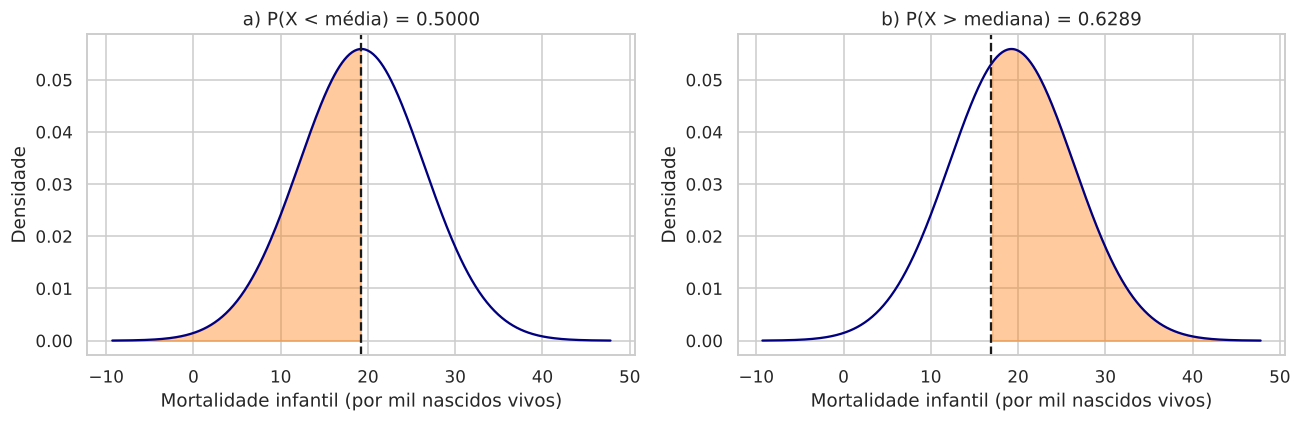

In [3]:
x = df["mort_infantil"]
mu, sigma = x.mean(), x.std(ddof=0)      # parâmetros populacionais (todos os municípios)
mediana = x.median()

def classifica(p):
    if np.isclose(p, 0): return "evento impossível"
    if np.isclose(p, 1): return "evento certo"
    if np.isclose(p, 0.5, atol=1e-6): return "evento equiprovável (50%)"
    return "evento provável (p > 50%)" if p > 0.5 else "evento improvável / pouco provável (p < 50%)"

# a) P(X < média)
z_a = (mu - mu) / sigma
p_a = stats.norm.cdf(z_a)
# b) P(X > mediana)
z_b = (mediana - mu) / sigma
p_b = 1 - stats.norm.cdf(z_b)

print(f"Média = {mu:.4f} | Desvio padrão = {sigma:.4f} | Mediana = {mediana:.4f}")
print(f"a) P(X < {mu:.2f}) = P(Z < {z_a:.4f}) = {p_a:.4f} ({100*p_a:.2f}%) -> {classifica(p_a)}")
print(f"b) P(X > {mediana:.2f}) = P(Z > {z_b:.4f}) = {p_b:.4f} ({100*p_b:.2f}%) -> {classifica(p_b)}")
RES["normal"] = dict(media=mu, dp=sigma, mediana=mediana, z_a=z_a, p_a=p_a, class_a=classifica(p_a),
                     z_b=z_b, p_b=p_b, class_b=classifica(p_b))

xs = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, lim, lado, titulo, p in [(ax[0], mu, "esq", "a) P(X < média)", p_a), (ax[1], mediana, "dir", "b) P(X > mediana)", p_b)]:
    a.plot(xs, stats.norm.pdf(xs, mu, sigma), color="navy")
    m = xs <= lim if lado == "esq" else xs >= lim
    a.fill_between(xs[m], stats.norm.pdf(xs[m], mu, sigma), alpha=.4, color="tab:orange")
    a.axvline(lim, ls="--", color="k")
    a.set_title(f"{titulo} = {p:.4f}"); a.set_xlabel("Mortalidade infantil (por mil nascidos vivos)"); a.set_ylabel("Densidade")
plt.tight_layout(); plt.savefig(FIG / "02_normal.png", bbox_inches="tight"); plt.show()

**Interpretação.** (a) Em uma distribuição normal a média é o centro de simetria, logo P(X < média) = 0,5: é um **evento equiprovável**.
(b) Como a mediana observada (16,9) é menor que a média (19,25) — a distribuição real é assimétrica à direita —, sob o modelo normal a probabilidade de um
município ter mortalidade infantil acima da mediana é maior que 50%: **evento provável**. Note que, empiricamente, essa proporção é exatamente 50%;
a diferença evidencia que a hipótese de normalidade é uma simplificação (ver limitações).

## 03) Testes de hipóteses para a média (teste Z)
Variável: **`mort_infantil`**. Média e desvio padrão populacionais = todos os 5.565 municípios. Amostras aleatórias com semente fixa (reprodutível).

In [4]:
mu0, sigma0 = mu, sigma

def teste_z(n, alpha, cauda, seed):
    amostra = x.sample(n=n, random_state=seed)
    xbar = amostra.mean()
    z = (xbar - mu0) / (sigma0 / np.sqrt(n))
    if cauda == "esquerda":
        zc = stats.norm.ppf(alpha); p = stats.norm.cdf(z); rejeita = z < zc
        h1 = f"H1: μ < {mu0:.4f}"
    else:
        zc = stats.norm.ppf(1 - alpha); p = 1 - stats.norm.cdf(z); rejeita = z > zc
        h1 = f"H1: μ > {mu0:.4f}"
    print(f"H0: μ = {mu0:.4f}  |  {h1}  |  α = {alpha:.0%}  |  n = {n}  |  σ = {sigma0:.4f}")
    print(f"Média amostral = {xbar:.4f} | Z calculado = {z:.4f} | Z crítico = {zc:.4f} | p-valor = {p:.4f}")
    print("Decisão:", "REJEITA H0" if rejeita else "NÃO rejeita H0")
    return dict(n=n, alpha=alpha, cauda=cauda, xbar=xbar, z=z, zc=zc, p=p, rejeita=bool(rejeita),
                amostra=amostra.round(2).tolist())

print("a) Teste unilateral à esquerda"); RES["teste_a"] = teste_z(20, 0.06, "esquerda", seed=42)
print("\nb) Teste unilateral à direita");  RES["teste_b"] = teste_z(25, 0.09, "direita", seed=7)

a) Teste unilateral à esquerda
H0: μ = 19.2470  |  H1: μ < 19.2470  |  α = 6%  |  n = 20  |  σ = 7.1360
Média amostral = 17.6250 | Z calculado = -1.0165 | Z crítico = -1.5548 | p-valor = 0.1547
Decisão: NÃO rejeita H0

b) Teste unilateral à direita
H0: μ = 19.2470  |  H1: μ > 19.2470  |  α = 9%  |  n = 25  |  σ = 7.1360
Média amostral = 19.0600 | Z calculado = -0.1310 | Z crítico = 1.3408 | p-valor = 0.5521
Decisão: NÃO rejeita H0


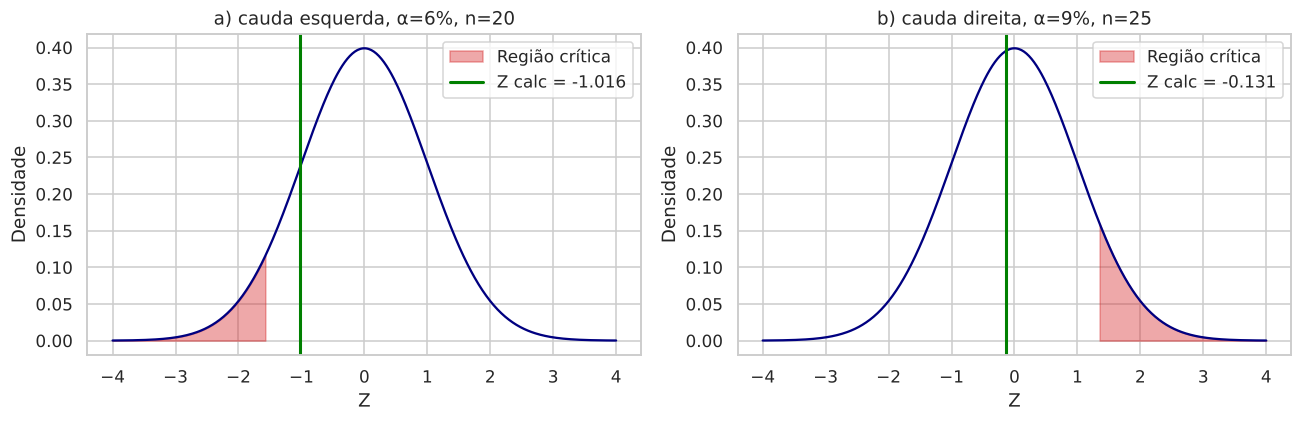

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
zs = np.linspace(-4, 4, 400)
for a, r, t in [(ax[0], RES["teste_a"], "a) cauda esquerda, α=6%, n=20"), (ax[1], RES["teste_b"], "b) cauda direita, α=9%, n=25")]:
    a.plot(zs, stats.norm.pdf(zs), color="navy")
    m = zs <= r["zc"] if r["cauda"] == "esquerda" else zs >= r["zc"]
    a.fill_between(zs[m], stats.norm.pdf(zs[m]), color="tab:red", alpha=.4, label="Região crítica")
    a.axvline(r["z"], color="green", lw=2, label=f"Z calc = {r['z']:.3f}")
    a.set_title(t); a.set_xlabel("Z"); a.set_ylabel("Densidade"); a.legend()
plt.tight_layout(); plt.savefig(FIG / "03_testes_hipotese.png", bbox_inches="tight"); plt.show()

**Interpretação.** Em ambos os casos a estatística Z ficou **fora da região crítica**, logo **não se rejeita H0**: não há evidência estatística,
aos níveis de 6% e 9%, de que a média de mortalidade infantil das amostras seja menor (a) ou maior (b) que a média nacional de referência.
As diferenças observadas são compatíveis com a variação natural de amostras aleatórias pequenas (n = 20 e n = 25).

## 04) Análise bivariada
**X = `pct_agua_esgoto_inadeq`** (saneamento inadequado, %) e **Y = `mort_infantil`**.

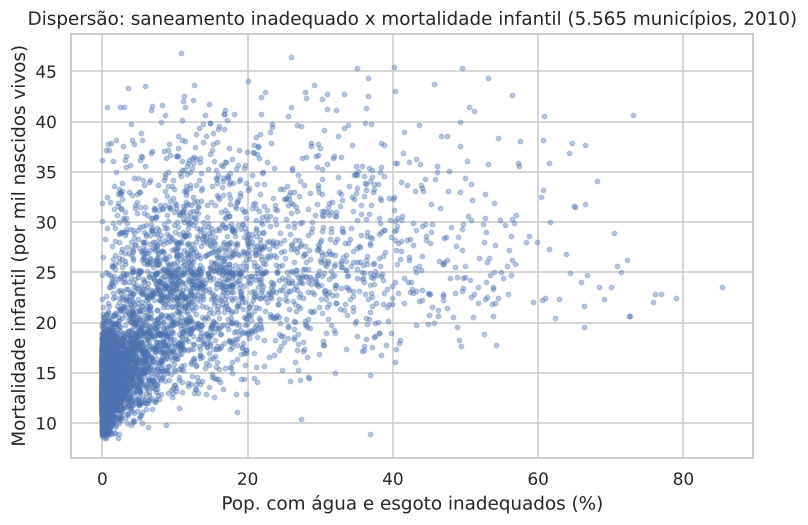

In [6]:
X1, Y = "pct_agua_esgoto_inadeq", "mort_infantil"
LBL = {"pct_agua_esgoto_inadeq": "Pop. com água e esgoto inadequados (%)", "mort_infantil": "Mortalidade infantil (por mil nascidos vivos)",
       "pct_coleta_lixo": "Pop. com coleta de lixo (%)", "renda_per_capita": "Renda per capita (R$)",
       "pct_analf_18mais": "Analfabetismo 18+ (%)", "pct_urbanizacao": "Urbanização (%)"}
# a) dispersão
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df[X1], df[Y], s=8, alpha=.35)
ax.set_title("Dispersão: saneamento inadequado x mortalidade infantil (5.565 municípios, 2010)")
ax.set_xlabel(LBL[X1]); ax.set_ylabel(LBL[Y])
plt.savefig(FIG / "04a_dispersao.png", bbox_inches="tight"); plt.show()

**a)** A nuvem de pontos mostra **tendência crescente**: municípios com maior parcela da população sem água e esgoto adequados tendem a ter mortalidade infantil maior. Há grande concentração de municípios com saneamento inadequado próximo de 0% e dispersão considerável de Y para um mesmo X (outros fatores também atuam).

In [7]:
# b) covariância e correlação
cov = df[[X1, Y]].cov().iloc[0, 1]
r, p_r = stats.pearsonr(df[X1], df[Y])
print(f"Covariância = {cov:.4f}")
print(f"Correlação de Pearson r = {r:.4f} (p-valor = {p_r:.3g})")
RES["bivariada"] = dict(cov=cov, r=r, p_r=p_r)

Covariância = 55.9742
Correlação de Pearson r = 0.6109 (p-valor = 0)


**b)** A covariância é **positiva**, indicando que as variáveis variam no mesmo sentido (sua magnitude depende das unidades, por isso não mede força). O coeficiente de Pearson r ≈ 0,61 indica **correlação linear positiva moderada** (0,5 ≤ |r| < 0,7) e estatisticamente significativa (p-valor ≈ 0).

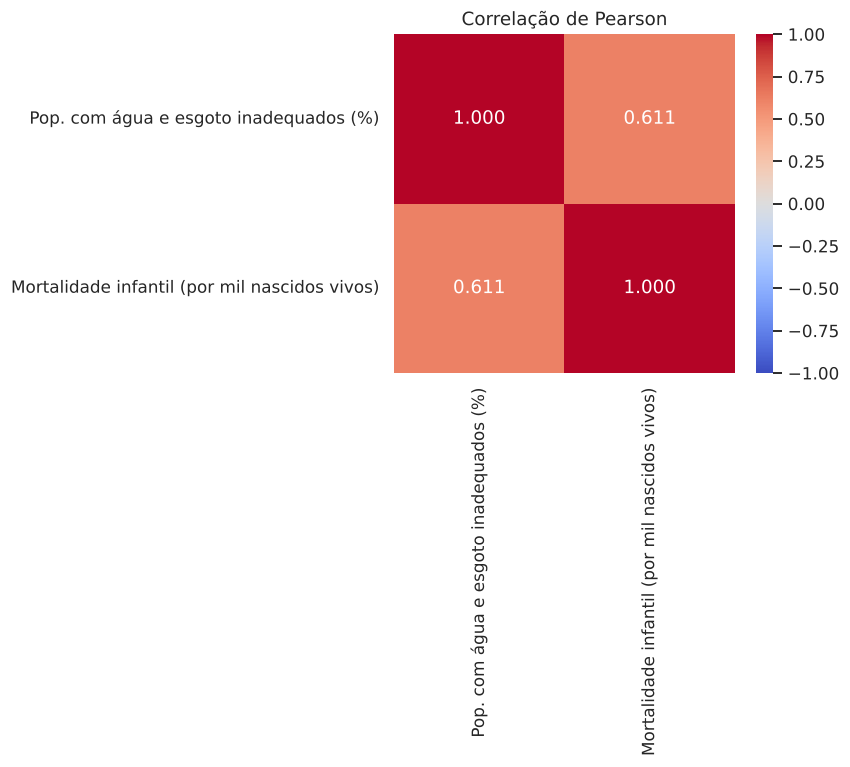

In [8]:
# c) gráfico de correlação
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(df[[X1, Y]].rename(columns=LBL).corr(), annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação de Pearson")
plt.savefig(FIG / "04c_correlacao.png", bbox_inches="tight"); plt.show()

**c)** O mapa de calor confirma visualmente r ≈ 0,61 (cor avermelhada = correlação positiva). A diagonal vale 1 (correlação de cada variável consigo mesma).

Equação: mort_infantil = 16.1225 + 0.3396 * pct_agua_esgoto_inadeq


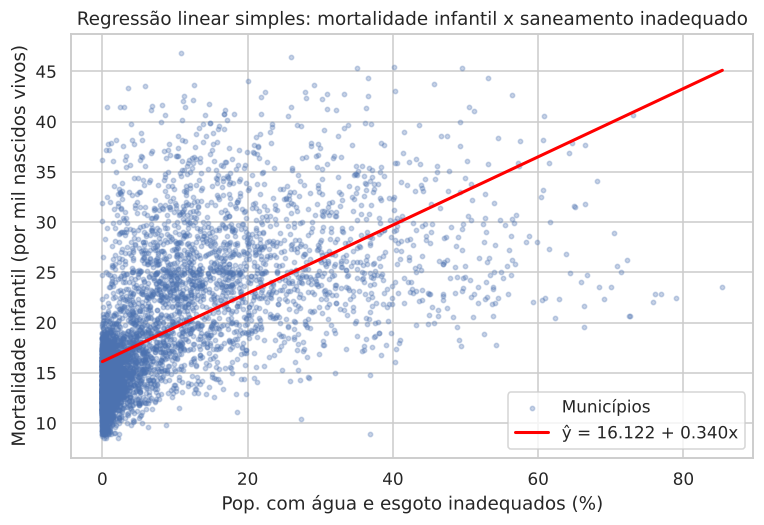

In [9]:
# d) regressão linear simples
mod_s = smf.ols(f"{Y} ~ {X1}", data=df).fit()
b0, b1 = mod_s.params
print(f"Equação: mort_infantil = {b0:.4f} + {b1:.4f} * pct_agua_esgoto_inadeq")
xx = np.linspace(df[X1].min(), df[X1].max(), 100)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df[X1], df[Y], s=8, alpha=.3, label="Municípios")
ax.plot(xx, b0 + b1*xx, color="red", lw=2, label=f"ŷ = {b0:.3f} + {b1:.3f}x")
ax.set_title("Regressão linear simples: mortalidade infantil x saneamento inadequado")
ax.set_xlabel(LBL[X1]); ax.set_ylabel(LBL[Y]); ax.legend()
plt.savefig(FIG / "04d_regressao_simples.png", bbox_inches="tight"); plt.show()

In [10]:
# e) adequação: R² e teste F
alpha_f = 0.05
f_crit = stats.f.ppf(1 - alpha_f, mod_s.df_model, mod_s.df_resid)
print(f"R² = {mod_s.rsquared:.4f} | R² ajustado = {mod_s.rsquared_adj:.4f}")
print(f"F = {mod_s.fvalue:.2f} | F crítico (5%) = {f_crit:.4f} | p-valor = {mod_s.f_pvalue:.3g}")
print(mod_s.summary().tables[1])
# f) previsão
novo = pd.DataFrame({X1: [5, 20, 40]})
prev = mod_s.get_prediction(novo).summary_frame(alpha=0.05)
prev.insert(0, X1, novo[X1])
print(prev[[X1, "mean", "obs_ci_lower", "obs_ci_upper"]].round(2))
RES["simples"] = dict(b0=b0, b1=b1, r2=mod_s.rsquared, r2adj=mod_s.rsquared_adj, F=mod_s.fvalue, Fcrit=f_crit,
                      pF=mod_s.f_pvalue, prev=prev[[X1, "mean", "obs_ci_lower", "obs_ci_upper"]].round(3).to_dict(orient="records"))

R² = 0.3732 | R² ajustado = 0.3731
F = 3311.89 | F crítico (5%) = 3.8431 | p-valor = 0
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 16.1225      0.093    172.995      0.000      15.940      16.305
pct_agua_esgoto_inadeq     0.3396      0.006     57.549      0.000       0.328       0.351
   pct_agua_esgoto_inadeq   mean  obs_ci_lower  obs_ci_upper
0                       5  17.82          6.74         28.90
1                      20  22.91         11.83         33.99
2                      40  29.70         18.62         40.79


**d)** A inclinação positiva indica que cada **1 ponto percentual** a mais de população com água/esgoto inadequados está associado a ≈ 0,34 óbito
infantil a mais por mil nascidos vivos. O intercepto (≈ 16,1) é a mortalidade esperada com saneamento 100% adequado.

**e)** R² ≈ 0,37: o saneamento sozinho explica cerca de 37% da variação da mortalidade infantil entre municípios. O teste F (F calculado muito maior que
o F crítico, p-valor ≈ 0) rejeita H0: β1 = 0, ou seja, **o modelo é estatisticamente significativo**, embora explique pouco mais de um terço da variabilidade.

**f)** Previsões pontuais (com intervalo de predição de 95%) para municípios com 5%, 20% e 40% da população sem saneamento adequado — ver tabela.

## 05) Regressão linear múltipla
Y = `mort_infantil`; X = `pct_agua_esgoto_inadeq`, `pct_coleta_lixo`, `renda_per_capita`, `pct_analf_18mais`, `pct_urbanizacao`.

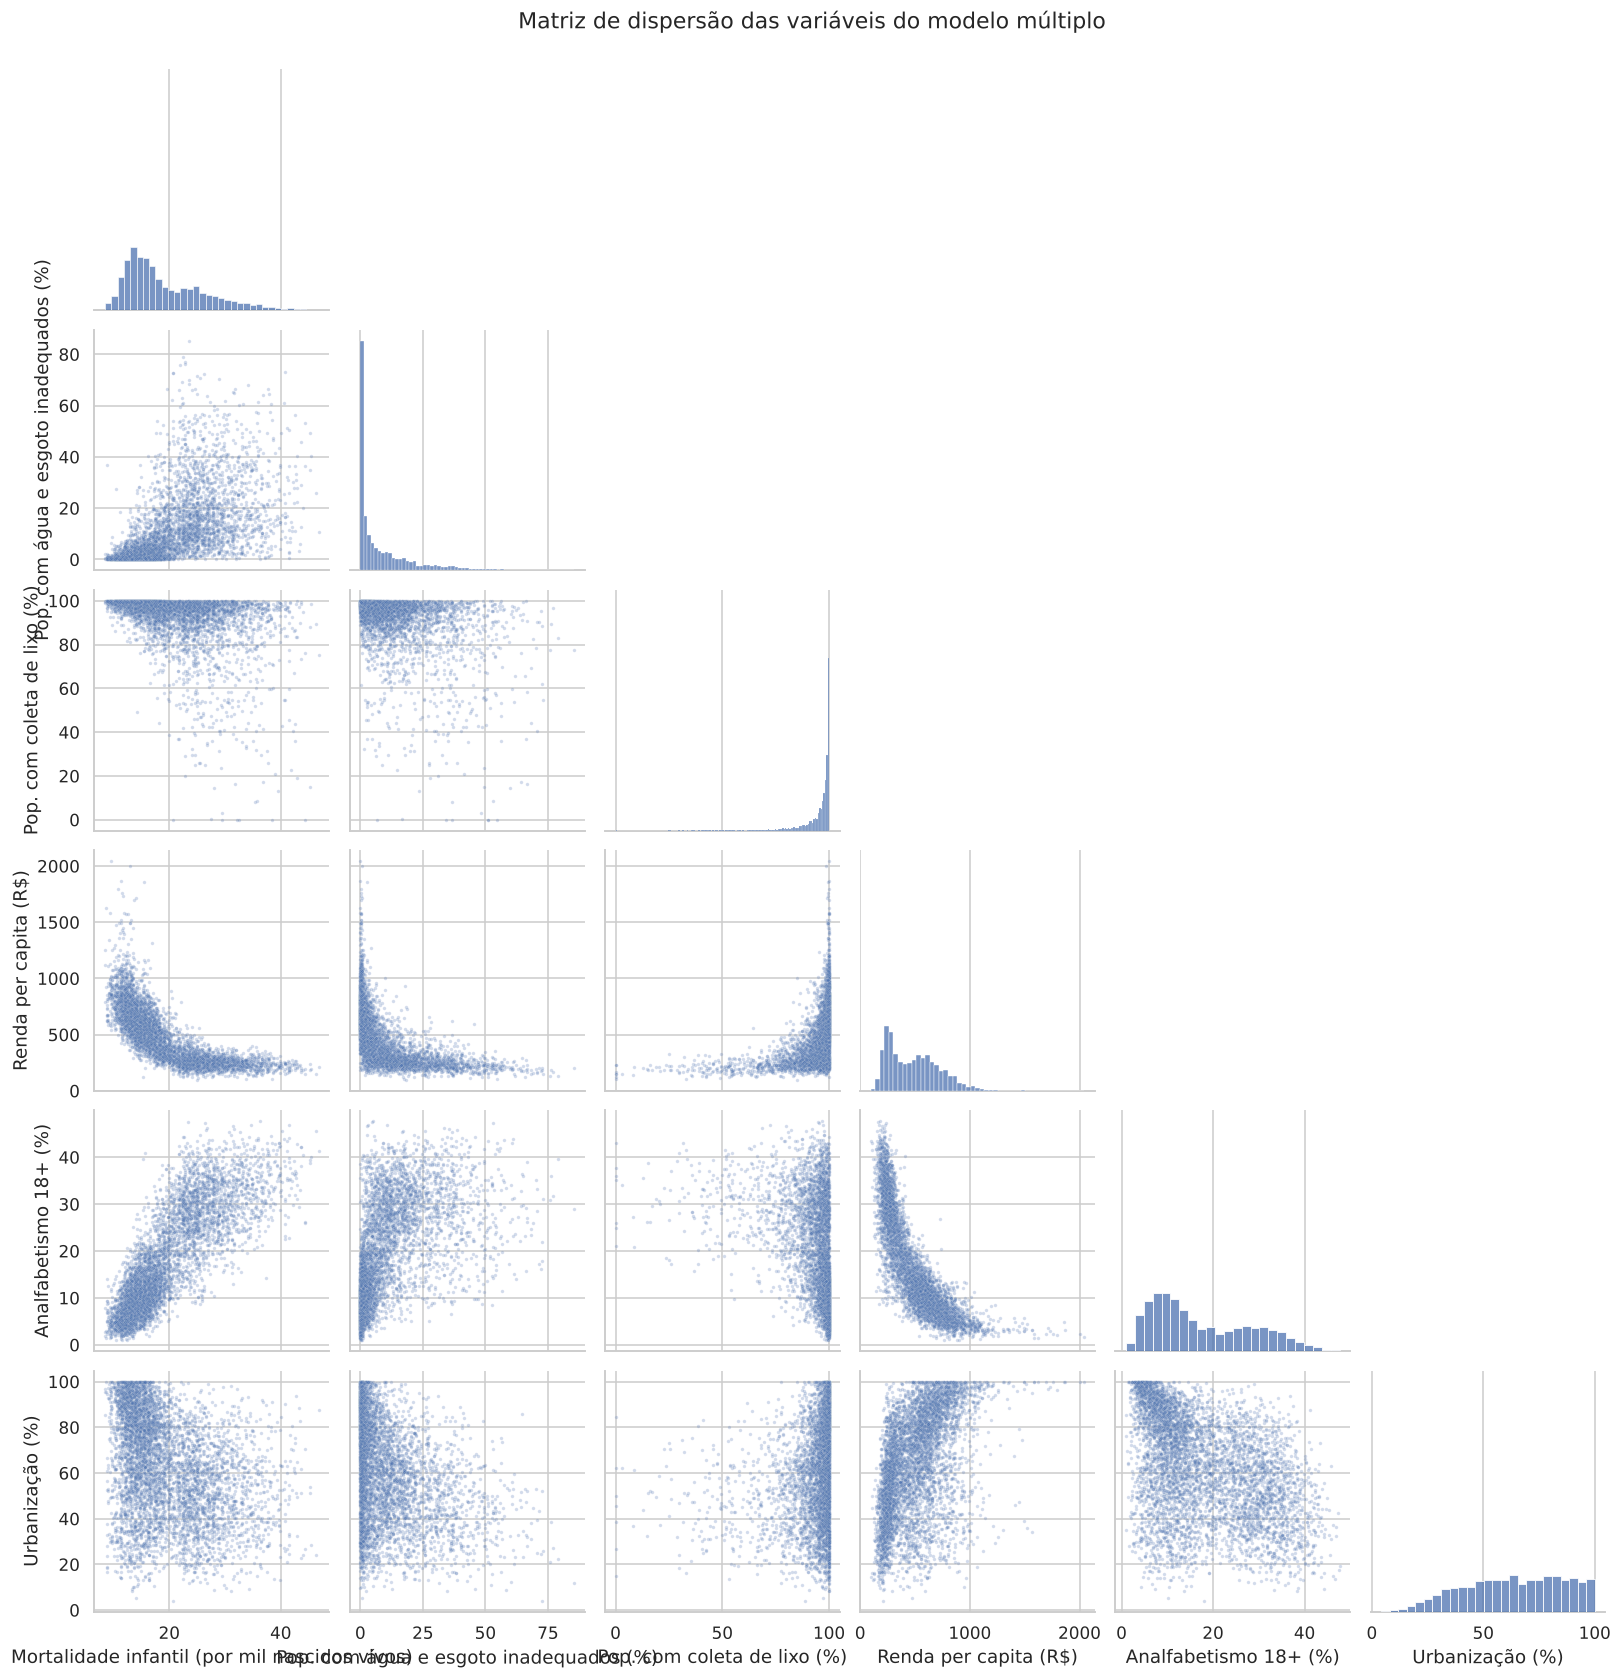

In [11]:
XM = ["pct_agua_esgoto_inadeq", "pct_coleta_lixo", "renda_per_capita", "pct_analf_18mais", "pct_urbanizacao"]
# a) dispersão (pairplot)
g = sns.pairplot(df[[Y] + XM].rename(columns=LBL), plot_kws=dict(s=5, alpha=.25), corner=True)
g.fig.suptitle("Matriz de dispersão das variáveis do modelo múltiplo", y=1.02)
g.savefig(FIG / "05a_pairplot.png", bbox_inches="tight"); plt.show()

**a)** A mortalidade infantil cresce com o saneamento inadequado e com o analfabetismo (relações crescentes nítidas) e diminui com a renda per capita (relação decrescente, levemente curva), com a coleta de lixo e com a urbanização. As explicativas também se relacionam entre si (ex.: renda x analfabetismo), sinal de multicolinearidade.

In [12]:
# b) matrizes de covariância e correlação
cov_m = df[[Y] + XM].cov(); cor_m = df[[Y] + XM].corr()
RES["cor_matriz"] = cor_m.round(3).to_dict()
print("Matriz de covariância:"); display(cov_m.round(2))
print("Matriz de correlação de Pearson:"); display(cor_m.round(3))

Matriz de covariância:


,mort_infantil,pct_agua_esgoto_inadeq,pct_coleta_lixo,renda_per_capita,pct_analf_18mais,pct_urbanizacao
mort_infantil,50.93,55.97,-34.80,-1291.00,63.14,-56.99
pct_agua_esgoto_inadeq,55.97,164.84,-66.44,-1831.86,80.38,-114.07
pct_coleta_lixo,-34.80,-66.44,122.09,1130.86,-48.85,61.32
renda_per_capita,-1291.00,-1831.86,1130.86,59179.97,-2127.84,2609.11
pct_analf_18mais,63.14,80.38,-48.85,-2127.84,114.47,-108.13
pct_urbanizacao,-56.99,-114.07,61.32,2609.11,-108.13,485.81


Matriz de correlação de Pearson:


,mort_infantil,pct_agua_esgoto_inadeq,pct_coleta_lixo,renda_per_capita,pct_analf_18mais,pct_urbanizacao
mort_infantil,1.000,0.611,-0.441,-0.744,0.827,-0.362
pct_agua_esgoto_inadeq,0.611,1.000,-0.468,-0.587,0.585,-0.403
pct_coleta_lixo,-0.441,-0.468,1.000,0.421,-0.413,0.252
renda_per_capita,-0.744,-0.587,0.421,1.000,-0.818,0.487
pct_analf_18mais,0.827,0.585,-0.413,-0.818,1.000,-0.459
pct_urbanizacao,-0.362,-0.403,0.252,0.487,-0.459,1.000


**b)** A covariância só indica o sentido (unidades diferentes). Na correlação, a mortalidade infantil tem associação **forte** com analfabetismo (r ≈ 0,83) e renda (r ≈ −0,74), **moderada** com saneamento inadequado (r ≈ 0,61) e coleta de lixo (r ≈ −0,44) e **fraca** com urbanização (r ≈ −0,36). Renda e analfabetismo são fortemente correlacionados entre si (r ≈ −0,77), o que sugere cautela ao interpretar coeficientes isolados.

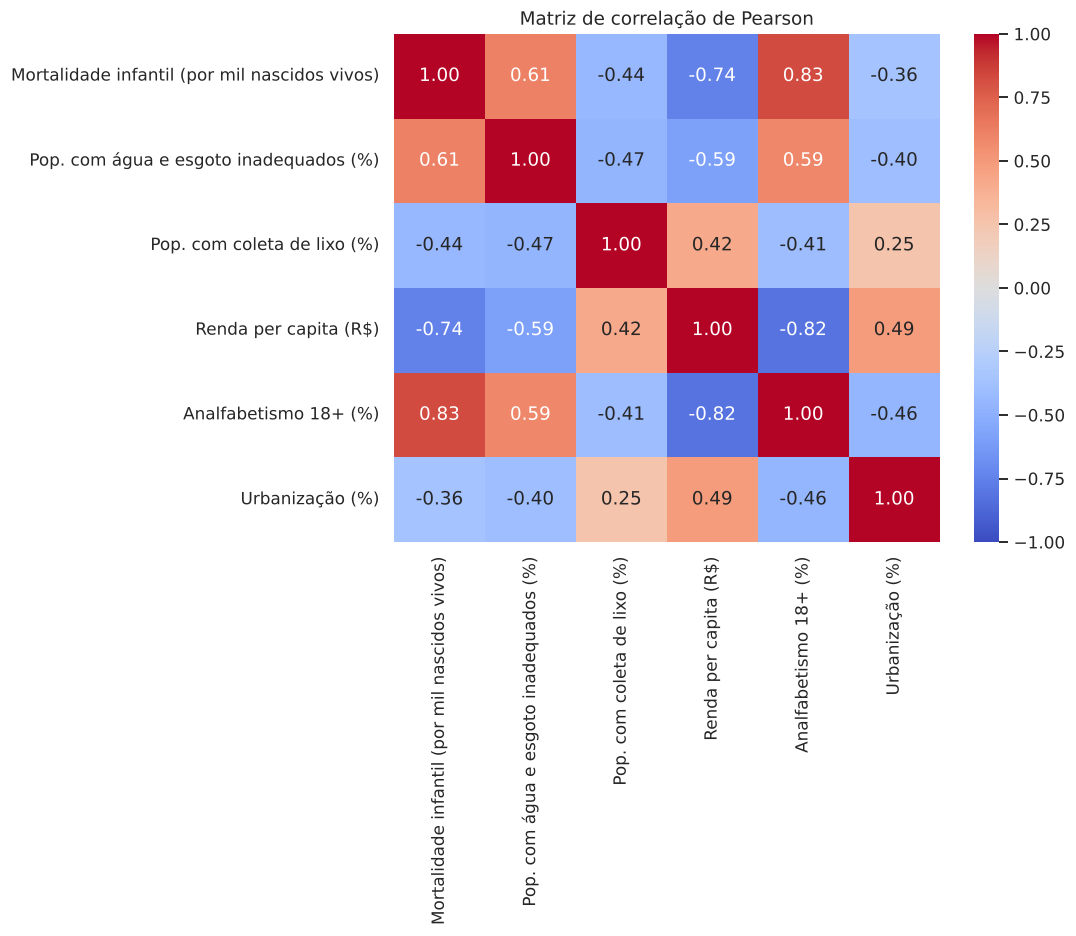

In [13]:
# c) gráfico de correlação
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cor_m.rename(index=LBL, columns=LBL), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Matriz de correlação de Pearson")
plt.savefig(FIG / "05c_correlacao_matriz.png", bbox_inches="tight"); plt.show()

**c)** O mapa de calor destaca em vermelho as associações positivas (saneamento inadequado e analfabetismo com mortalidade) e em azul as negativas (renda, coleta de lixo e urbanização).

In [14]:
# d) equação e e) adequação
mod_m = smf.ols(f"{Y} ~ " + " + ".join(XM), data=df).fit()
eq = f"mort_infantil = {mod_m.params['Intercept']:.4f}" + "".join(
    f" {'+' if mod_m.params[v] >= 0 else '-'} {abs(mod_m.params[v]):.5f}*{v}" for v in XM)
print("Equação:", eq)
f_crit_m = stats.f.ppf(0.95, mod_m.df_model, mod_m.df_resid)
print(f"R² = {mod_m.rsquared:.4f} | R² ajustado = {mod_m.rsquared_adj:.4f}")
print(f"F = {mod_m.fvalue:.2f} | F crítico (5%) = {f_crit_m:.4f} | p-valor = {mod_m.f_pvalue:.3g}")
print(mod_m.summary())
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xv = sm.add_constant(df[XM])
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=XM, name="VIF")
print(vif.round(2))
RES["multipla"] = dict(eq=eq, params=mod_m.params.to_dict(), pvalues=mod_m.pvalues.to_dict(), r2=mod_m.rsquared,
                       r2adj=mod_m.rsquared_adj, F=mod_m.fvalue, Fcrit=f_crit_m, pF=mod_m.f_pvalue, vif=vif.to_dict())

Equação: mort_infantil = 16.1208 + 0.08871*pct_agua_esgoto_inadeq - 0.04276*pct_coleta_lixo - 0.00472*renda_per_capita + 0.40671*pct_analf_18mais + 0.02481*pct_urbanizacao
R² = 0.7228 | R² ajustado = 0.7226
F = 2899.54 | F crítico (5%) = 2.2157 | p-valor = 0
                            OLS Regression Results                            
Dep. Variable:          mort_infantil   R-squared:                       0.723
Model:                            OLS   Adj. R-squared:                  0.723
Method:                 Least Squares   F-statistic:                     2900.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:03:09   Log-Likelihood:                -15262.
No. Observations:                5565   AIC:                         3.054e+04
Df Residuals:                    5559   BIC:                         3.058e+04
Df Model:                           5                                         
Covariance Type:            no

In [15]:
# f) previsão com 5 variáveis explicativas (≥ 2 exigidas)
cenarios = pd.DataFrame({
    "cenario": ["Município com saneamento precário", "Mesmo município após universalizar água/esgoto e lixo", "Município médio brasileiro"],
    "pct_agua_esgoto_inadeq": [30, 0, df["pct_agua_esgoto_inadeq"].mean()],
    "pct_coleta_lixo": [80, 100, df["pct_coleta_lixo"].mean()],
    "renda_per_capita": [300, 300, df["renda_per_capita"].mean()],
    "pct_analf_18mais": [25, 25, df["pct_analf_18mais"].mean()],
    "pct_urbanizacao": [50, 50, df["pct_urbanizacao"].mean()],
})
pm = mod_m.get_prediction(cenarios).summary_frame(alpha=0.05)
cenarios["mort_prevista"] = pm["mean"].values
cenarios["IP95_inf"] = pm["obs_ci_lower"].values; cenarios["IP95_sup"] = pm["obs_ci_upper"].values
RES["prev_multipla"] = cenarios.round(3).to_dict(orient="records")
cenarios.round(2)

,cenario,pct_agua_esgoto_inadeq,pct_coleta_lixo,renda_per_capita,pct_analf_18mais,pct_urbanizacao,mort_prevista,IP95_inf,IP95_sup
0,Município com saneamento precário,30.0,80.00,300.00,25.0,50.00,25.35,17.98,32.72
1,Mesmo município após universalizar água/esgoto...,0.0,100.00,300.00,25.0,50.00,21.84,14.46,29.21
2,Município médio brasileiro,9.2,94.05,493.61,17.4,63.83,19.25,11.88,26.62


**d/e)** O modelo múltiplo explica cerca de **73% da variação** (R² ≈ 0,73), um ganho expressivo frente ao modelo simples (≈ 37%). O teste F
rejeita H0 (todos os β = 0), logo o modelo é globalmente significativo. Mantidas as demais variáveis constantes, saneamento inadequado e
analfabetismo aumentam a mortalidade infantil, enquanto renda e coleta de lixo a reduzem; todos os coeficientes são significativos (p < 0,05).
O analfabetismo é o preditor de maior peso (+0,41 ‰ por ponto percentual). A urbanização, que isoladamente tem correlação negativa, passa a ter
coeficiente levemente **positivo** quando se controla por renda e escolaridade — efeito típico de variáveis correlacionadas, que não deve ser lido como causal.
Os VIFs ficam abaixo de 5 (multicolinearidade moderada e aceitável).

**f)** A comparação entre os dois primeiros cenários mostra o efeito estimado de universalizar água, esgoto e coleta de lixo num município pobre,
mantendo renda, escolaridade e urbanização: a mortalidade infantil prevista cai de ≈ 25,4 para ≈ 21,8 por mil nascidos vivos (≈ 3,5 óbitos a menos por mil nascidos vivos).

## 06) Regressão logística binária
Variável resposta **`alta_mortalidade`** = 1 se a mortalidade infantil do município é **maior que a mediana nacional** (16,9 ‰), 0 caso contrário
(classes balanceadas). Explicativas: `pct_agua_esgoto_inadeq`, `pct_coleta_lixo`, `renda_per_capita` (em centenas de R$) e `pct_analf_18mais`.
Os dados são divididos em treino (70%) e teste (30%) para avaliar a classificação com dados não vistos.

In [16]:
corte = df["mort_infantil"].median()
dl = df.copy()
dl["alta_mortalidade"] = (dl["mort_infantil"] > corte).astype(int)
dl["renda_100"] = dl["renda_per_capita"] / 100
XL = ["pct_agua_esgoto_inadeq", "pct_coleta_lixo", "renda_100", "pct_analf_18mais"]
print("Corte (mediana):", corte); print(dl["alta_mortalidade"].value_counts())
treino, teste = train_test_split(dl, test_size=0.3, random_state=42, stratify=dl["alta_mortalidade"])
logit = smf.logit("alta_mortalidade ~ " + " + ".join(XL), data=treino).fit()
print(logit.summary())
p = logit.params
eq_l = "logit(p) = ln(p/(1-p)) = " + f"{p['Intercept']:.4f}" + "".join(f" {'+' if p[v] >= 0 else '-'} {abs(p[v]):.4f}*{v}" for v in XL)
print("\na) Equação:", eq_l)
print("   p = 1 / (1 + e^-(logit))")
odds = np.exp(p).rename("odds_ratio"); print(odds.round(4))

Corte (mediana): 16.9
alta_mortalidade
0    2783
1    2782
Name: count, dtype: int64
Optimization terminated successfully.
         Current function value: 0.271884
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:       alta_mortalidade   No. Observations:                 3895
Model:                          Logit   Df Residuals:                     3890
Method:                           MLE   Df Model:                            4
Date:                Thu, 12 Nov 2026   Pseudo R-squ.:                  0.6078
Time:                        20:03:09   Log-Likelihood:                -1059.0
converged:                       True   LL-Null:                       -2699.8
Covariance Type:            nonrobust   LLR p-value:                     0.000
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------

[[768  67]
 [105 730]]
Acurácia teste = 0.8970 | treino = 0.8829 | sensibilidade = 0.8743 | especificidade = 0.9198


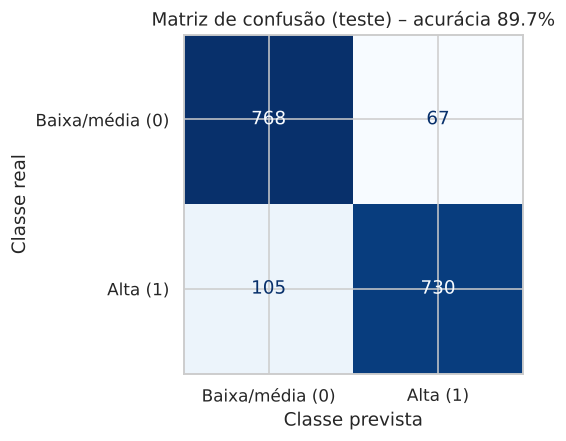

In [17]:
# b) matriz de confusão e acurácia (base de teste, limiar 0,5)
prob_teste = logit.predict(teste)
pred = (prob_teste >= 0.5).astype(int)
cm = confusion_matrix(teste["alta_mortalidade"], pred)
acc = accuracy_score(teste["alta_mortalidade"], pred)
acc_treino = accuracy_score(treino["alta_mortalidade"], (logit.predict(treino) >= 0.5).astype(int))
vn, fp, fn, vp = cm.ravel()
sens, espec = vp / (vp + fn), vn / (vn + fp)
print(cm); print(f"Acurácia teste = {acc:.4f} | treino = {acc_treino:.4f} | sensibilidade = {sens:.4f} | especificidade = {espec:.4f}")
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Baixa/média (0)", "Alta (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusão (teste) – acurácia {acc:.1%}"); ax.set_xlabel("Classe prevista"); ax.set_ylabel("Classe real")
plt.savefig(FIG / "06b_matriz_confusao.png", bbox_inches="tight"); plt.show()
RES["logistica"] = dict(corte=corte, eq=eq_l, params=p.to_dict(), pvalues=logit.pvalues.to_dict(), odds=odds.to_dict(),
                        cm=cm.tolist(), acc=acc, acc_treino=acc_treino, sens=sens, espec=espec,
                        pseudo_r2=logit.prsquared, n_treino=len(treino), n_teste=len(teste))

In [18]:
# c) classificação de novos municípios (4 variáveis explicativas)
novos = pd.DataFrame({
    "municipio_hipotetico": ["A – saneamento precário e baixa renda", "B – boa infraestrutura e renda média", "C – precário em saneamento, mas renda média"],
    "pct_agua_esgoto_inadeq": [35, 1, 25], "pct_coleta_lixo": [75, 99, 90],
    "renda_100": [2.5, 7.0, 5.0], "pct_analf_18mais": [28, 6, 12],
})
novos["prob_alta_mortalidade"] = logit.predict(novos)
novos["classificacao"] = np.where(novos["prob_alta_mortalidade"] >= 0.5, "ALTA mortalidade (1)", "Baixa/média mortalidade (0)")
RES["class_logistica"] = novos.round(4).to_dict(orient="records")
novos.round(4)

,municipio_hipotetico,pct_agua_esgoto_inadeq,pct_coleta_lixo,renda_100,pct_analf_18mais,prob_alta_mortalidade,classificacao
0,A – saneamento precário e baixa renda,35,75,2.5,28,0.9971,ALTA mortalidade (1)
1,B – boa infraestrutura e renda média,1,99,7.0,6,0.0415,Baixa/média mortalidade (0)
2,"C – precário em saneamento, mas renda média",25,90,5.0,12,0.7531,ALTA mortalidade (1)


**a)** Coeficientes positivos (saneamento inadequado, analfabetismo) aumentam a chance de o município estar no grupo de alta mortalidade; coeficientes
negativos (renda, coleta de lixo) a reduzem. A razão de chances (odds ratio = e^β) mostra o efeito multiplicativo: cada +1 p.p. de saneamento inadequado
multiplica a chance de alta mortalidade por ≈ 1,09; cada +1 p.p. de analfabetismo, por ≈ 1,13; cada +R$ 100 de renda, por ≈ 0,53 (redução de ≈ 47%).
A coleta de lixo não foi estatisticamente significativa neste modelo (p ≈ 0,14), quando controlada pelas demais.

**b)** A matriz de confusão compara o real com o previsto na base de teste. A acurácia (acertos / total) de ≈ 89,7% é bem superior aos 50% de um
classificador aleatório (classes balanceadas), e as acurácias de treino (88,3%) e teste são próximas (sem sinal de sobreajuste). O modelo erra mais
nos falsos negativos (105 municípios de alta mortalidade classificados como baixa) do que nos falsos positivos (67) — sensibilidade ≈ 87% e
especificidade ≈ 92%. Para uso em políticas públicas, onde deixar de identificar um município crítico é mais grave, pode-se reduzir o limiar de 0,5.

**c)** O modelo classifica municípios hipotéticos a partir de 4 variáveis explicativas — ver tabela acima.

In [19]:
with open(RAIZ / "relatorio" / "resultados.json", "w", encoding="utf-8") as f:
    json.dump(RES, f, ensure_ascii=False, indent=2, default=float)
print("Resultados salvos em relatorio/resultados.json")

Resultados salvos em relatorio/resultados.json
